# Clase de transformada rapida Fourier,

En esta clase vamos a trabajar el concepto de trasnformada discreta fourier desde los principios fundamentales de la construcción del concepto, ilustrando un implementación intuitiva (DFT) no optimal (FFT), pero que permita ver que sucede al interior de los paquetes ya programados como numpy y scipy, y comparar con el código realizado en clase. adicionalmente, se presenta un ejemplo donde el estudiante pueda ver, una señal de datos sintéticos, el espectro de potencia, y se pueda aplicar alguna máscara en el espacio reciproco para mostrar como se hace el filtrado y que efectos tiene en el espacio original.

Se van a usar paquetes básicos como numpy y matplotlib, y se va tener en cuenta que los estudiantes vienes de cursos básicos de programación como IP. Que puede graficar, llenar arreglo y calcular algunas funciones elementales.

Al final, se muestran un par de aplicaciones y recursos on-line que le permita al estdiante conectar con física y con ciencias de la computación.


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, ifft, fftfreq


In [79]:
#Definimos frecuencia
f = 1
fs = 5 # Medidas por segundos (sampleo)

In [80]:
t = np.linspace(0.,1.,2*fs, endpoint=False)

# Señal periodica
x = np.cos(2*np.pi*f*t) + 4.*np.sin(4*np.pi*f*t)
#x = np.sin( np.sqrt(t) )

print(x)

[ 1.          4.61324306  2.660158   -2.660158   -4.61324306 -1.
  2.99520907  2.04212401 -2.04212401 -2.99520907]


Text(0, 0.5, '$tiempo[s]$')

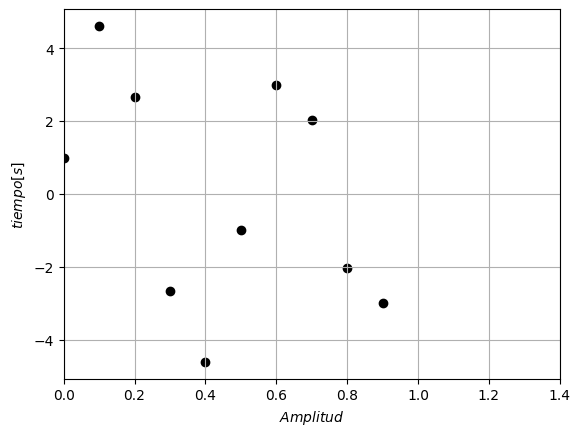

In [81]:
plt.figure()
plt.scatter(t,x, c='black')
plt.grid()
plt.xlim(0,1.4)
plt.xlabel(r'$Amplitud$')
plt.ylabel(r'$tiempo[s]$')

# Podemos pensar en este muestreo que viene de un experimento, laboratorio, etc
# Queremos encontrar la transformada rápida de Fourier que tiene complejita NLog(N), pero Primero buscamos una implementación naive (Discreta NXN), para entender el concepto y la implementación detras de los paquetes profesionales que se usan para realizar este cálculo.

In [82]:
def GetFFT(x):

    Npoints = len(x)
    c = (2.0*np.pi)/len(x)

    fft = []

    for k in range(Npoints):

        Re= 0.
        Im= 0.

        for n in range(Npoints):

            Re += x[n]*np.cos( c*k*n )
            Im -= x[n]*np.sin( c*k*n )

        fft = np.append(fft, complex(Re,Im))

    return fft



# En este bloque se le muestra al estudiante una implementación intuitiva de la transformada

In [83]:
Xw = GetFFT(x)
print(Xw)

[-4.44089210e-16+0.00000000e+00j  5.00000000e+00+2.22044605e-15j
  2.44249065e-15-2.00000000e+01j -7.77156117e-16+8.88178420e-16j
 -8.88178420e-16+1.11022302e-15j  4.44089210e-15+1.16719256e-15j
  4.44089210e-16+1.33226763e-15j -8.54871729e-15+9.32587341e-15j
 -2.00950367e-14+2.00000000e+01j  5.00000000e+00-6.66133815e-16j]


In [84]:
# En esta parte se realiza una comparasión con el resultado entregado por la transformada de NUmpy

# FFT de numpy
Xw1 = fft(x)

#Xw1 = np.abs(Xw1)
print(Xw1)

[ 8.88178420e-16+0.00000000e+00j  5.00000000e+00+2.88657986e-15j
 -2.32528129e-15-2.00000000e+01j  4.44089210e-16-2.66241948e-18j
 -3.39253968e-16+1.77635684e-15j  4.08006962e-15+1.57599743e-17j
 -3.39253968e-16-1.77635684e-15j  5.27355937e-16+3.04705857e-17j
 -2.32528129e-15+2.00000000e+01j  5.00000000e+00-2.93014800e-15j]


# Posterior, se realiza la implementación de la transformada inversa (Naive implementation)

In [85]:
# Implementar la transformada inversa

def GetIFFT(x):

    Npoints = len(x)
    c = (2.0*np.pi)/len(x)

    ifft = []

    for k in range(Npoints):

        Re = 0.
        Im = 0.

        for n in range(Npoints):

            Re += x[n]*np.cos( c*k*n )
            Im += x[n]*np.sin( c*k*n )

        ifft = np.append(ifft, complex(Re, Im)/Npoints)

    return ifft

In [86]:
Xt = ifft(Xw) #
Xt1 = GetIFFT(Xw1)

print(Xt)
print(Xt1)

[ 1.        +1.58221365e-15j  4.61324306+1.52641082e-15j
  2.660158  -1.02117456e-15j -2.660158  -2.68659810e-15j
 -4.61324306-2.06468832e-15j -1.        -1.32959041e-15j
  2.99520907+2.31013989e-15j  2.04212401+4.39559355e-15j
 -2.04212401-2.22894373e-16j -2.99520907-2.48941215e-15j]
[ 1.        +4.17527935e-16j  4.61324306-5.03507479e-16j
  2.660158  -9.78724973e-16j -2.660158  +1.24517850e-15j
 -4.61324306+2.23545540e-15j -1.        +9.05338200e-16j
  2.99520907-2.24984562e-15j  2.04212401-7.97631867e-16j
 -2.04212401+2.04108165e-15j -2.99520907+4.78115412e-15j]


# Comparar resultados,
# Se le muestra al estudiante como recuperar la señal orginal desde el espectro de potencias
# Se compara, la implementación de la clase, el resultado obtenido por paquetes ya implementados
# En esta parte de la clase, la comparasion es CUALITATIVA, SOLO BASADA EN LOS NUMEROS EN LISTA  y EN EL SCATTER PLOT

Text(0, 0.5, '$tiempo[s]$')

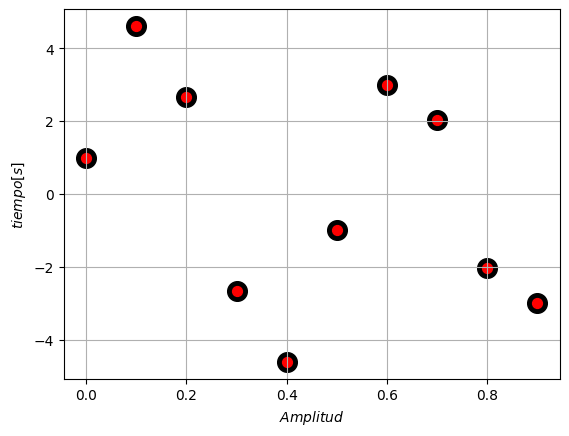

In [87]:
plt.figure()
plt.scatter(t,x, c='black', s=200)
# Para regresar al dominio temporal, solo tomamos la parte real.

#plt.scatter(t,Xt.real, c='red', s=50)
#plt.scatter(t,Xt1.real, c='blue', s=10)

plt.scatter(t,Xt1.real, c='red', s=50)
#plt.scatter(t,abs(Xt1), c='blue', s=10)

plt.grid()

plt.xlabel(r'$Amplitud$')
plt.ylabel(r'$tiempo[s]$')

# En la segunda parte de la clase:
# Se busca crear una señal sintética de varias componentes y en este caso, vamos a visualizar el espectro de potencial de la señal, mirando la apareción de frecuencias negativas y que significan, adicionalmente, se busca realizar masking y sus posibles aplicaciones, en tratamiento de sonido, mejoramiento de imagenes, etc

In [88]:
Fs = 2000      # Frecuencia de muestreo
tstep = 1 / Fs # intervalo de tiempo de muestreo
f0 = 100 # Signal frequency

N = int (Fs / f0)       # Numero de muestras

N = int (10 * Fs / f0)  # Podemos hacer mas ciclos

In [89]:
t = np.linspace(0, (N-1)*tstep, int(N))
#print(t)
fstep = Fs / N # Intervalo de frecuencias
freq = np.linspace(0, (N-1)*fstep, int(N))
#print(freq)

In [90]:
def GetSample(t,A,f0,modos=1):

  #  y = np.sqrt(t)
    y = 1.0 * A * np.sin(2 * np.pi * ( 1 * f0 ) * t)

    if modos == 2:
        y += 0.5 * A * np.sin( 2 * np.pi * ( 3 * f0) * t )
    elif modos == 3:
        y += 0.5 * A * np.sin( 2 * np.pi * ( 3 * f0) * t )
        y += 4.0 * A * np.sin( 2 * np.pi * ( 4 * f0) * t )

    return y

In [91]:
y = GetSample(t,1,f0,3)

In [92]:
# Calculamos la fft
X = np.fft.fft(y)
XMag = np.abs(X) / len(y)

In [93]:
freq2 = freq[0:int(N/2+1)]
XMag2 = 2.0*XMag[0:int(N/2+1)]
XMag2[0] = XMag2[0] / 2

Text(0.5, 0, 'Frequency[Hz]')

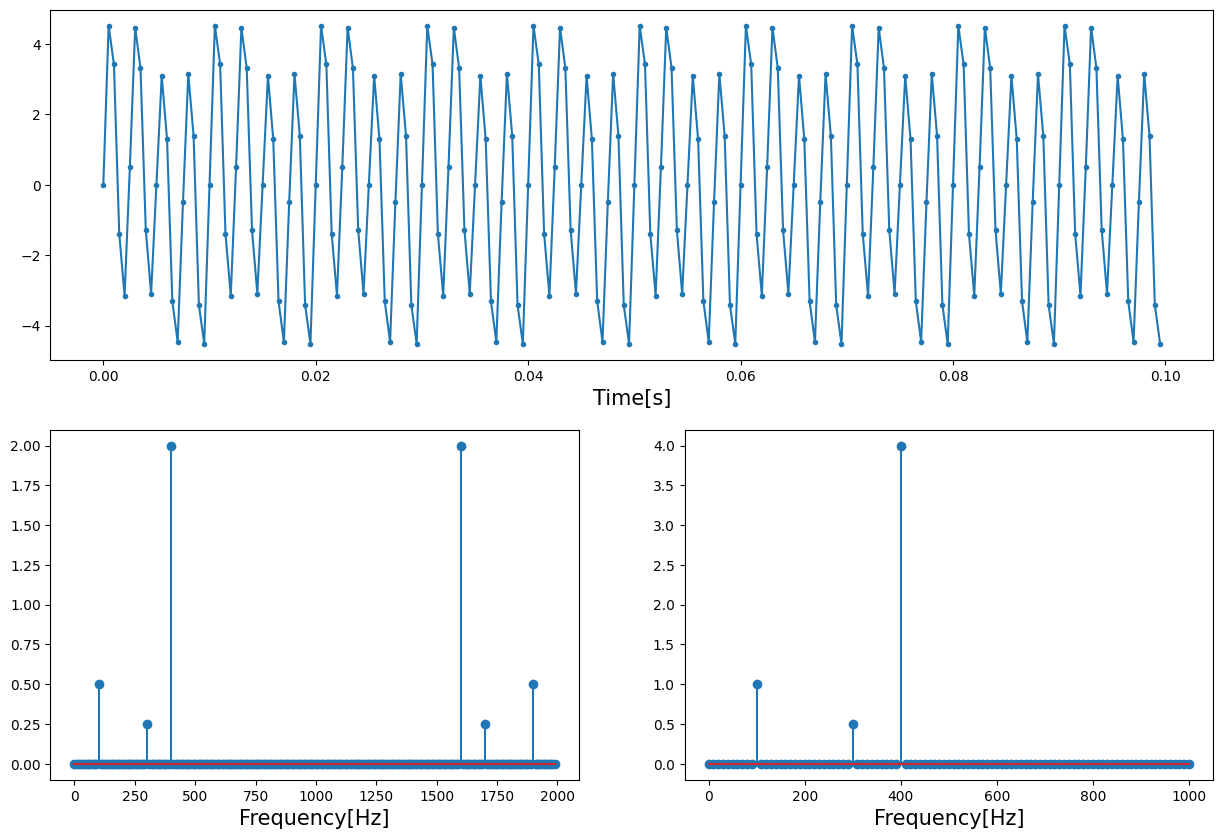

In [94]:
fig = plt.figure(figsize=(15,10))
ax = fig.add_subplot(2,1,1)
ax1 = fig.add_subplot(2,2,3)
ax2 = fig.add_subplot(2,2,4)
ax.plot(t,y,'.-')
ax.set_xlabel('Time[s]', fontsize=15)
ax1.stem(freq,XMag,'.-')
ax1.set_xlabel('Frequency[Hz]', fontsize=15)
ax2.stem(freq2,XMag2,'.-')
ax2.set_xlabel('Frequency[Hz]', fontsize=15)

# Realizar masking sobre el espectro de potencia

# El calculo del periodo de manchas solares se puede realizar mediante esta técnica por ejemplo

In [99]:
# Construimos una mascara
mask1 = freq > 350

In [100]:
X[mask1] = 0

In [101]:
XMag_ = np.abs(X) / len(y)
XMag2_ = 2.0*XMag_[0:int(N/2+1)]
XMag2_[0] = XMag2_[0] / 2

Text(0.5, 0, 'Frequency[Hz]')

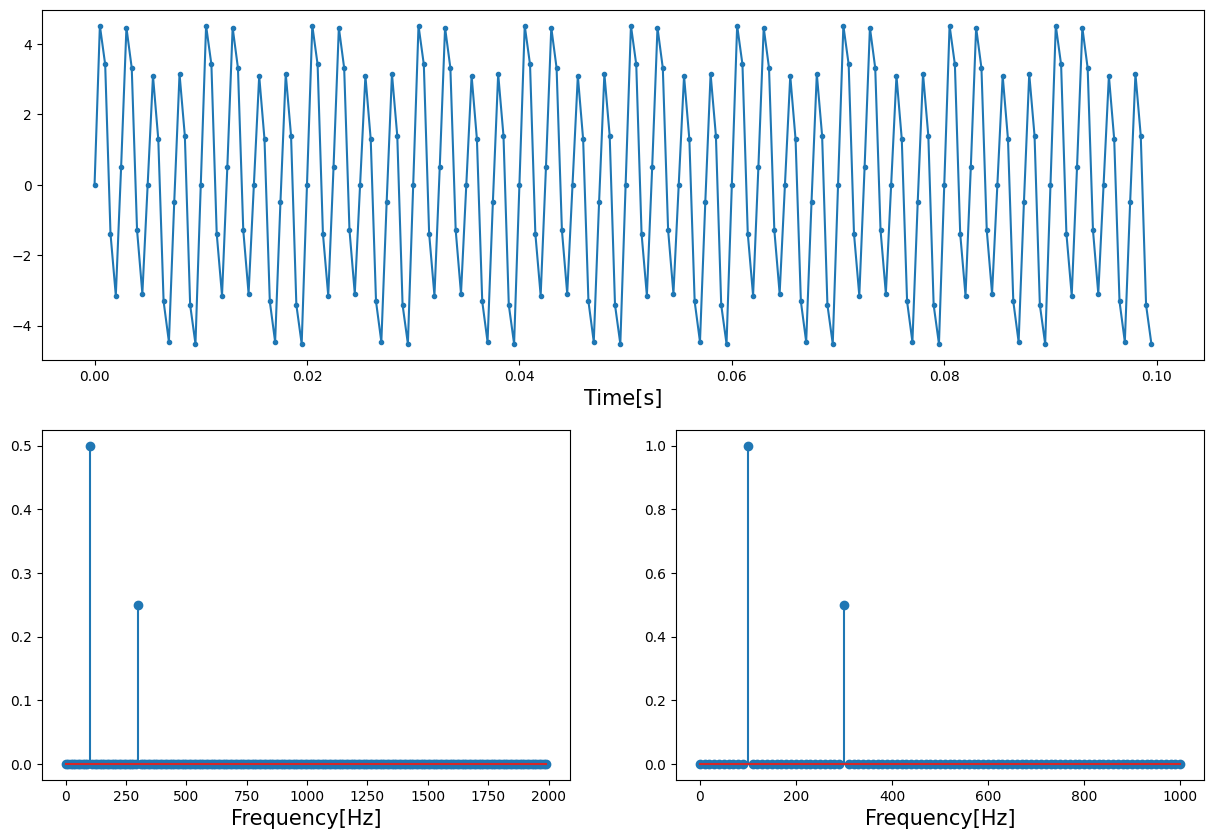

In [102]:
fig = plt.figure(figsize=(15,10))
ax = fig.add_subplot(2,1,1)
ax1 = fig.add_subplot(2,2,3)
ax2 = fig.add_subplot(2,2,4)
ax.plot(t,y,'.-')
ax.set_xlabel('Time[s]', fontsize=15)
ax1.stem(freq,XMag_,'.-')
ax1.set_xlabel('Frequency[Hz]', fontsize=15)
ax2.stem(freq2,XMag2_,'.-')
ax2.set_xlabel('Frequency[Hz]', fontsize=15)

# En esta última parte, se le muestra al estudiante cual es el efecto de la aplicación de la máscara, regresando a la serie temporal.

In [103]:
NewSample = np.fft.ifft(2*X)

In [104]:
y1 = GetSample(t,1,f0,2)

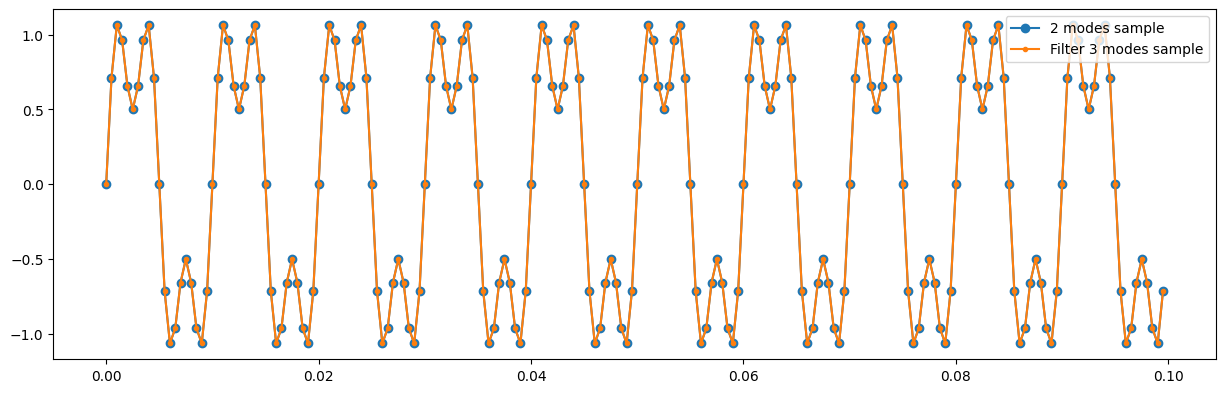

In [105]:
fig = plt.figure(figsize=(15,10))
ax = fig.add_subplot(2,1,1)
ax.plot(t,y1,marker='o',label='2 modes sample')
ax.plot(t,np.real(NewSample),'.-',label='Filter 3 modes sample')
plt.legend(loc=1)

# Aplicaciones, en tratamiento de sonido, mejoramiento de imagenes, etc
# Se utilizan referencias online, del uso y aplicaciíon.
# Tratamiendo de imagenes y sonido,
# Aplicación de la derivada espectral
# Solución espectral de ecuaciones diferenciales parciales.


https://www.youtube.com/watch?v=7haZCrQDHpA

https://www.youtube.com/watch?v=nl9TZanwbBk